In [41]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [42]:
url= "https://raw.githubusercontent.com/PakAirQuality/unveiling-Karachi-Air/main/PAQI_Daily" \
"_PM2.5_Data_2016-2024_in_Karachi.csv"
df=pd.read_csv(url)
print("Dataset loaded successfully!")



Dataset loaded successfully!


In [43]:
#Check the dimensions
df.shape

(3009, 2)

In [44]:
#Display First 5 rows
df.head(5)

,date,pm25_concentration_ug_per_m3
0,2016-10-06,22.0
1,2016-10-07,23.5
2,2016-10-08,18.7
3,2016-10-09,19.8
4,2016-10-10,22.3


In [45]:
#Display Columns name
df.columns.tolist()

['date', 'pm25_concentration_ug_per_m3']

In [46]:
#Check Data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3009 entries, 0 to 3008
Data columns (total 2 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          3009 non-null   str    
 1   pm25_concentration_ug_per_m3  3003 non-null   float64
dtypes: float64(1), str(1)
memory usage: 47.1 KB


In [47]:
#Check the data types
df.dtypes

date                                str
pm25_concentration_ug_per_m3    float64
dtype: object

In [48]:
#Convert the date Column
df["date"]=pd.to_datetime(df["date"])
df.dtypes

date                            datetime64[us]
pm25_concentration_ug_per_m3           float64
dtype: object

In [49]:
#Check for missing dates
df["date"].isnull().sum()

np.int64(0)

In [50]:
df.dtypes

date                            datetime64[us]
pm25_concentration_ug_per_m3           float64
dtype: object

In [51]:
#Check the date range 
print("Earliest data:",df["date"].min())
print("Latest date:",df["date"].max())

Earliest data: 2016-10-06 00:00:00
Latest date: 2024-12-31 00:00:00


In [52]:
#Check for duplicate dates
df.duplicated().sum()
df["date"].duplicated().sum()

np.int64(0)

In [53]:
#Check the PM25 measurements
df["pm25_concentration_ug_per_m3"].dtype

dtype('float64')

In [54]:
#Calculate descriptive statistics
df["pm25_concentration_ug_per_m3"].describe()

count    3003.000000
mean       48.157742
std        33.392841
min         1.300000
25%        25.000000
50%        35.800000
75%        63.850000
max       242.100000
Name: pm25_concentration_ug_per_m3, dtype: float64

In [55]:
#Check for negative values
(df["pm25_concentration_ug_per_m3"]<0).sum()

np.int64(0)

In [56]:
#Research 
#When did karachi experience it highest recorded PM2.5  Concentration
pm_col = "pm25_concentration_ug_per_m3"
highest_index = df[pm_col].idxmax()
df.loc[highest_index]

date                            2019-12-10 00:00:00
pm25_concentration_ug_per_m3                  242.1
Name: 1160, dtype: object

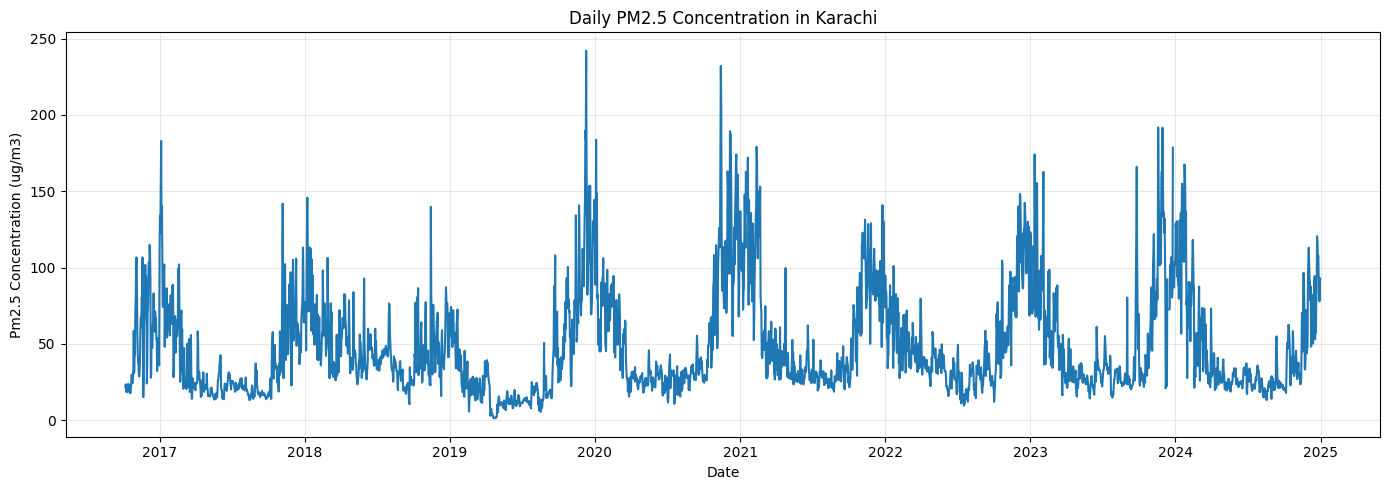

In [57]:
#Visualization
plt.figure(figsize=(14,5))
plt.plot(df["date"],df["pm25_concentration_ug_per_m3"])
plt.title("Daily PM2.5 Concentration in Karachi")
plt.xlabel("Date")
plt.ylabel("Pm2.5 Concentration (ug/m3)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Does karachi PM2.5 Concentration tend to be higher during certain months of the year

In [58]:
#Create a monthly Column
df["month"]=df["date"].dt.month

In [59]:
df.columns.tolist()

['date', 'pm25_concentration_ug_per_m3', 'month']

In [60]:
#Calculate average pollution for each month
pm_col = "pm25_concentration_ug_per_m3"
monthly_avg = df.groupby("month")[pm_col].mean()
monthly_avg

month
1     86.130242
2     62.743805
3     40.615323
4     32.384583
5     27.911290
6     27.823333
7     26.768548
8     25.472581
9     31.322917
10    43.617883
11    76.187407
12    90.247619
Name: pm25_concentration_ug_per_m3, dtype: float64

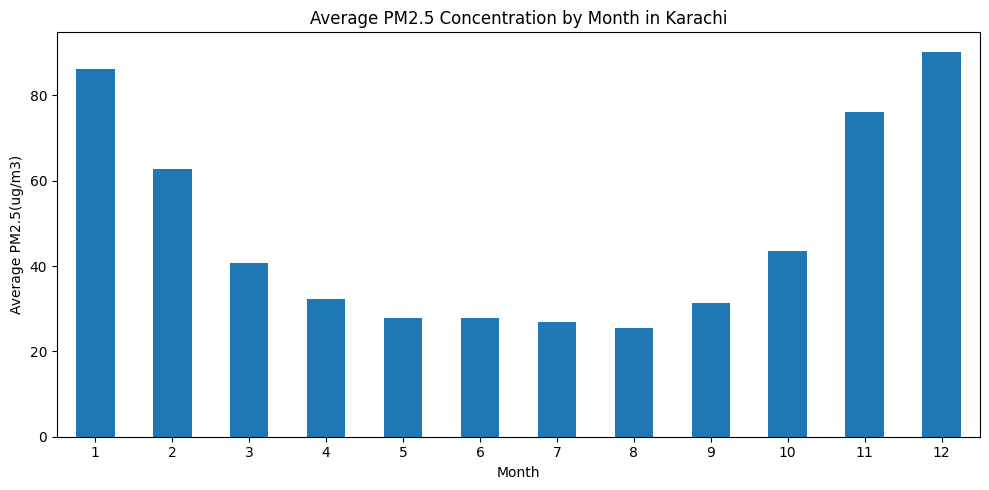

In [61]:
#Visualize the monthly averages
monthly_avg.plot(
    kind="bar",
    figsize=(10,5),
    title="Average PM2.5 Concentration by Month in Karachi"
)
plt.xlabel("Month")
plt.ylabel("Average PM2.5(ug/m3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [62]:
#Find the highest and lowest monthly averages
print("Highest monthly average:")
print(monthly_avg.idxmax(),monthly_avg.max())
print("Lowest monthly average:")
print(monthly_avg.idxmin(),monthly_avg.min())


Highest monthly average:
12 90.24761904761904
Lowest monthly average:
8 25.47258064516129


In [63]:
#Analyaze pollution by year
df["year"]=df["date"].dt.year
df[["date","year","month"]].head()

,date,year,month
0,2016-10-06,2016,10
1,2016-10-07,2016,10
2,2016-10-08,2016,10
3,2016-10-09,2016,10
4,2016-10-10,2016,10


In [64]:
#compare monthly pollution across years
# does december have high PM2.5 concentrations every year,or its overall  
#average influenced by only a few years?
year_month_avg= df.pivot_table(index="year",columns="month",
values=pm_col,aggfunc="mean"
)
year_month_avg


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.888462,62.996667,65.683871
2017,86.758065,60.028571,29.241935,25.886667,19.096774,24.380000,22.870968,19.151613,17.633333,32.106452,62.373333,67.658065
2018,84.164516,59.278571,44.577419,54.090000,41.703226,43.230000,42.480645,37.209677,23.096667,46.325806,49.846667,49.435484
2019,50.400000,23.878571,20.716129,13.253333,11.370968,12.350000,13.900000,17.622581,37.770000,55.206452,71.860000,122.841935
2020,81.719355,72.306897,42.016129,27.446667,26.196774,27.320000,26.232258,26.706452,33.836667,51.761290,109.283333,126.716129
2021,115.700000,103.117857,45.580645,41.733333,31.548387,32.710000,29.532258,24.516129,33.310000,54.300000,98.953333,90.793548
2022,65.825806,50.750000,45.006452,36.910000,40.509677,26.330000,20.964516,29.700000,33.003333,47.864516,74.780000,112.067742
2023,91.319355,64.378571,50.900000,29.570000,27.174194,29.636667,31.061290,27.835484,45.680000,36.451613,107.876667,93.956000
2024,113.154839,67.693103,46.883871,30.186667,25.690323,26.630000,27.106452,21.038710,26.253333,38.119355,47.716667,83.793548


In [65]:
year_month_avg.shape

(9, 12)

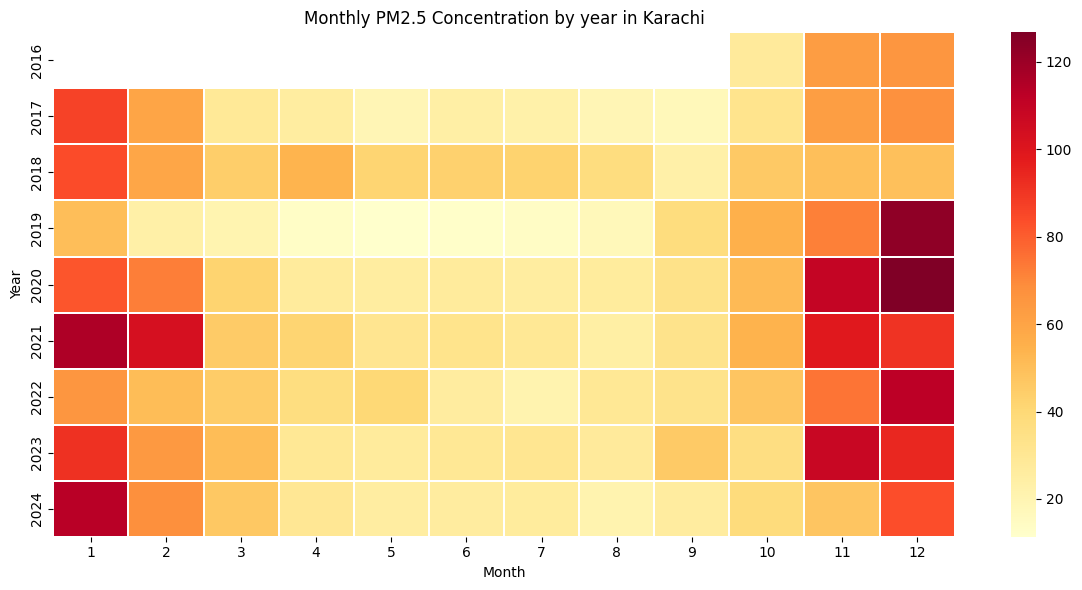

In [66]:
#Heatmap
plt.figure(figsize=(12,6))
sns.heatmap(
    year_month_avg,
    cmap="YlOrRd",
    linewidths=0.3
)
plt.title("Monthly PM2.5 Concentration by year in Karachi")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


In [67]:
#Find the year with highest average pollution
yearly_avg= df.groupby("year")[pm_col].mean().sort_values(ascending=False)
print(yearly_avg)

year
2021    58.190685
2020    54.249454
2016    53.462069
2023    52.204457
2022    48.689863
2018    47.919178
2024    46.218852
2017    38.828493
2019    37.751781
Name: pm25_concentration_ug_per_m3, dtype: float64


In [68]:
#lets find the actual average value for 2021
print(yearly_avg.head())

year
2021    58.190685
2020    54.249454
2016    53.462069
2023    52.204457
2022    48.689863
Name: pm25_concentration_ug_per_m3, dtype: float64


In [69]:
#Find the lowest pollution year
print(yearly_avg.tail())

year
2022    48.689863
2018    47.919178
2024    46.218852
2017    38.828493
2019    37.751781
Name: pm25_concentration_ug_per_m3, dtype: float64


In [70]:
#Verfication
print(yearly_avg.min())

37.751780821917805


In [71]:
#Compare two years 
#Lets calculate the difference between the highest and lowest annual averages
difference = yearly_avg.max()-yearly_avg.min()
print(round(difference,2))

20.44


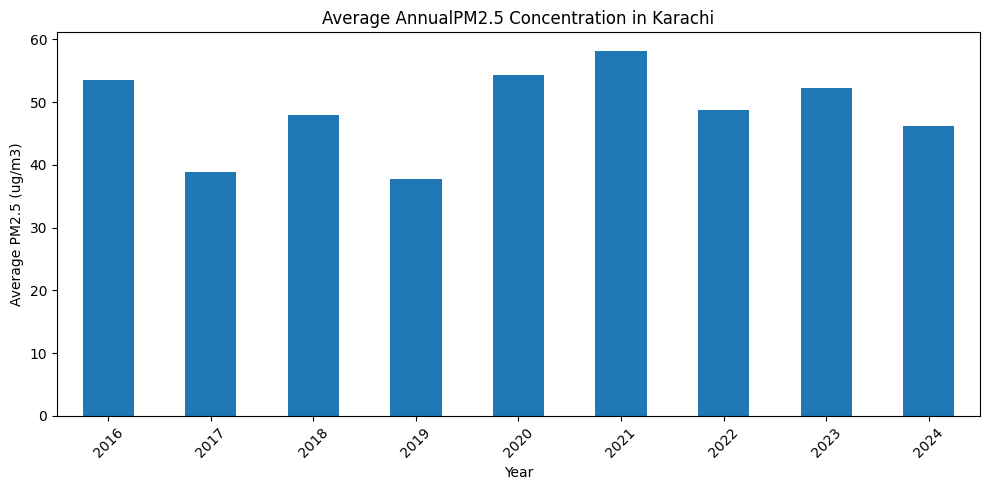

In [72]:
#Visualize the yearly averages
yearly_avg.sort_index().plot(kind="bar",figsize=(10,5),title="Average Annual" \
"PM2.5 Concentration in Karachi")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 (ug/m3)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [73]:
#Investigate the highest pollution month
print(monthly_avg.sort_values(ascending=False))

month
12    90.247619
1     86.130242
11    76.187407
2     62.743805
10    43.617883
3     40.615323
4     32.384583
9     31.322917
5     27.911290
6     27.823333
7     26.768548
8     25.472581
Name: pm25_concentration_ug_per_m3, dtype: float64


In [74]:
#Investigate the lowest pollution month
print(monthly_avg.sort_values(ascending=True))

month
8     25.472581
7     26.768548
6     27.823333
5     27.911290
9     31.322917
4     32.384583
3     40.615323
10    43.617883
2     62.743805
11    76.187407
1     86.130242
12    90.247619
Name: pm25_concentration_ug_per_m3, dtype: float64


#Conclusion 
This project explores daily PM2.5 air quality measurements in karachi from October 2016 to December 2024. Using Python, Pandas , Matplotlib, and Seaborn, I examined data quality, monthly patterns, annual averages,and variations in pollution over time.
The preliminary analysis found that December had the highest average monthly PM2.5 concentration (90.24ug/m3).The annual averages were highest in 2021 (58.19ug/m3) and lowest in 2019 (37.75ug/m3).
Six PM2.5 readings were , all in 2023. These values were left missing rather than replaced with estimates. the results describe patterns in the available 
dataset and do not establish the cause of pollution changes.
Limitations 
Missing  readings may affect comparsions between months and years
The analysis identifies patterns but does not establish causation 
The findings depend on the coverage and quality of the avaliable measurements.